# Convection, inversions and the shape of the wind

How a plume spreads depends on the **turbulence**, and the turbulence depends on two things:

- **Mechanical turbulence**: wind shear over the rough ground. It is stronger in stronger wind.
- **Buoyancy**:
  - *Daytime*: the sun heats the ground, the air near it becomes warmer than the air above, and
    warm parcels rise. This is **convection**, with large eddies and fast mixing.
  - *Night*: the ground cools by radiation, the air near it becomes colder than the air above,
    and vertical motion is suppressed. This is an **inversion**, or *stable* layer.

The quantity that compares the two is the **Richardson number**:

$$ Ri_b = \frac{g}{\bar T}\,\frac{\Delta\theta\,\Delta z}{(\Delta u)^2} $$

Here θ is the *potential temperature*, θ ≈ T + 0.0098·z: temperature corrected for the
cooling of air that rises adiabatically. A negative Ri means convection, a value near 0 means
neutral (shear only), and a positive value means stable. We compute it between 0.5 m and 8 m
from Table 8.1.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))  # notebooks/ (for pgdata)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pgdata
pgdata.style()
pd.set_option("display.precision", 3); pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)

In [2]:
rt = pgdata.run_table()
T, U = pgdata.profiles("temperature"), pgdata.profiles("wind_speed")
colors = pgdata.REGIME_COLORS
rt.regime.value_counts().to_frame().join(rt.groupby("regime", observed=True).day_night.agg(lambda s: s.value_counts().to_dict()))

,count,day_night
regime,,
convective,32,{'day': 32}
stable,31,{'night': 31}
near-neutral,3,{'night': 3}


## 1. Temperature profiles: the fingerprint of stability

Each line is one release, plotted as temperature minus the temperature at 1 m. The height axis
is logarithmic, because most of the change happens in the first metre or two. Convective runs
lean left (cooler aloft) and stable runs lean right (warmer aloft: the inversion).

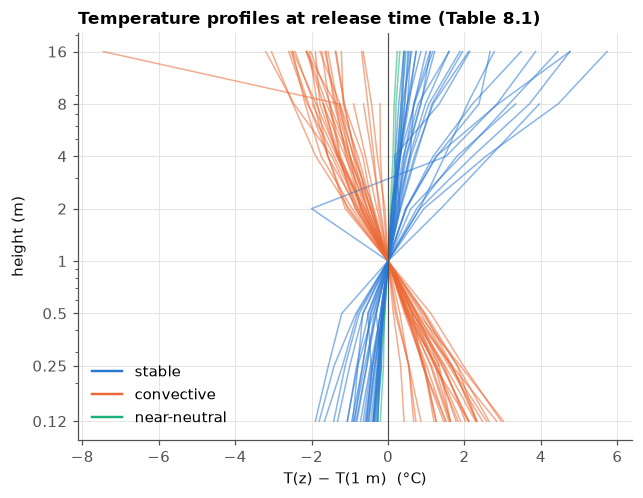

In [3]:
air = [h for h in T.columns if h > 0]
fig, ax = plt.subplots(figsize=(6.5, 4.8))
for run, row in T[air].iterrows():
    reg = rt.regime.get(run)
    if pd.isna(reg):
        continue
    prof = (row - row[1.0]).dropna()
    ax.plot(prof.values, prof.index, color=colors[reg], alpha=0.55, lw=1)
for reg, c in colors.items():
    ax.plot([], [], color=c, label=reg)
ax.axvline(0, color=pgdata.MUTED, lw=0.8)
ax.set_yscale("log"); ax.set_yticks(air, [f"{h:g}" for h in air])
ax.set_xlabel("T(z) − T(1 m)  (°C)"); ax.set_ylabel("height (m)"); ax.legend()
ax.set_title("Temperature profiles at release time (Table 8.1)"); plt.show()

## 2. The diurnal cycle, from the hourly Table 8.2

The releases are a sample of times. Table 8.2 covers the hours in between, and it shows the
whole cycle. Stability flips sign shortly after sunrise and again before sunset, driven by
**net radiation** (sunshine in minus heat radiated out). Net radiation crosses zero at about the
same times.

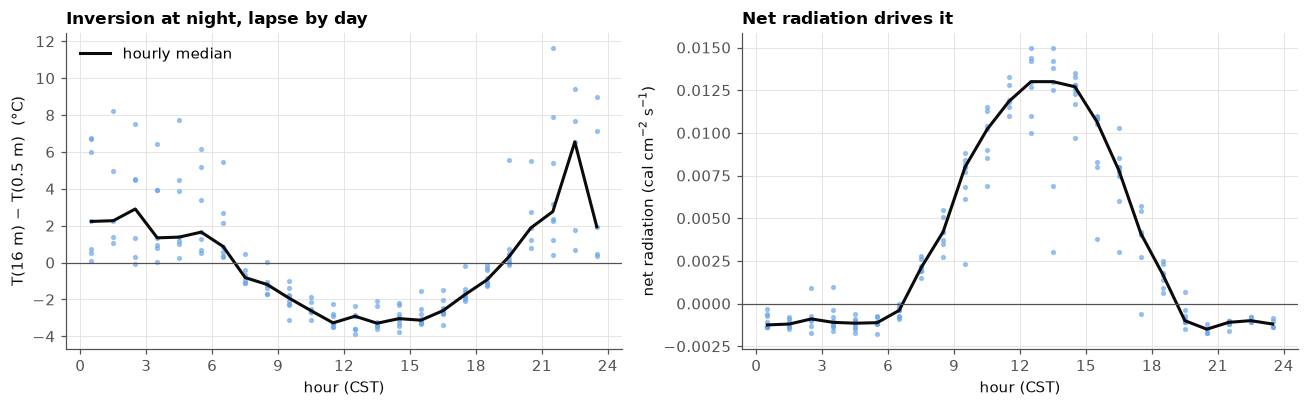

In [4]:
T2 = pgdata.profiles("temperature", table="8.2")
mm2 = pgdata.micromet("8.2")
rn2 = mm2[mm2.quantity == "net_radiation"].set_index(["date", "cst"]).value
rn2 = rn2[rn2.abs() < 0.033]
d2 = pd.DataFrame({"dT": T2.get(16.0) - T2.get(0.5)}).join(rn2.rename("Rn"))
d2["hour"] = d2.index.get_level_values("cst").astype(int) // 100 + 0.5
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
for ax, col, lab in [(axes[0], "dT", "T(16 m) − T(0.5 m)  (°C)"), (axes[1], "Rn", "net radiation (cal cm$^{-2}$ s$^{-1}$)")]:
    ax.scatter(d2.hour, d2[col], s=6, color=pgdata.ARC_COLORS[100], alpha=0.6)
    med = d2.groupby("hour")[col].median()
    ax.plot(med.index, med.values, color=pgdata.INK, lw=2, label="hourly median")
    ax.axhline(0, color=pgdata.MUTED, lw=0.8); ax.set_ylabel(lab); ax.set_xlabel("hour (CST)")
axes[0].set_title("Inversion at night, lapse by day"); axes[1].set_title("Net radiation drives it")
axes[0].legend(); axes[0].set_xticks(range(0, 25, 3)); plt.tight_layout(); plt.show()

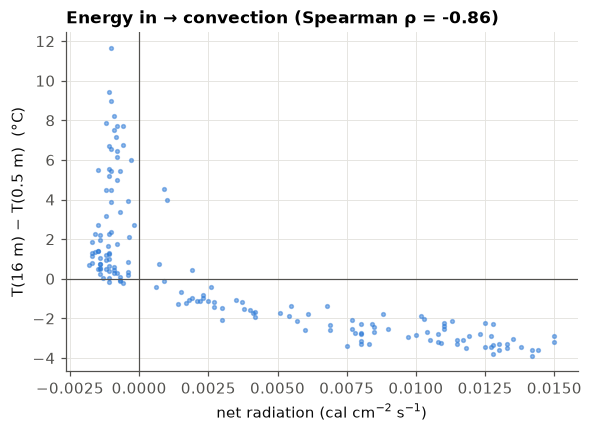

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(d2.Rn, d2.dT, s=6, color=pgdata.ARC_COLORS[200], alpha=0.5)
ax.axhline(0, color=pgdata.MUTED, lw=0.8); ax.axvline(0, color=pgdata.MUTED, lw=0.8)
ax.set_xlabel("net radiation (cal cm$^{-2}$ s$^{-1}$)"); ax.set_ylabel("T(16 m) − T(0.5 m)  (°C)")
ax.set_title(f"Energy in → convection (Spearman ρ = {d2[['Rn','dT']].corr('spearman').iloc[0,1]:.2f})")
plt.show()

## 3. The wind profile and the logarithmic law

Close to the ground in neutral conditions, wind speed grows with the **logarithm** of height:

$$ u(z) = \frac{u_*}{\kappa}\ln\frac{z}{z_0} $$

- $u_*$, the *friction velocity*, measures how hard the wind pulls on the surface.
- $z_0$, the *roughness length*, is a property of the ground (short grass: a few mm to a cm).
- κ = 0.4 is von Kármán's constant.

Plot u against ln z and a neutral profile is a **straight line**. Convection bends it one way
(mixing evens the speed out aloft) and stability bends it the other.

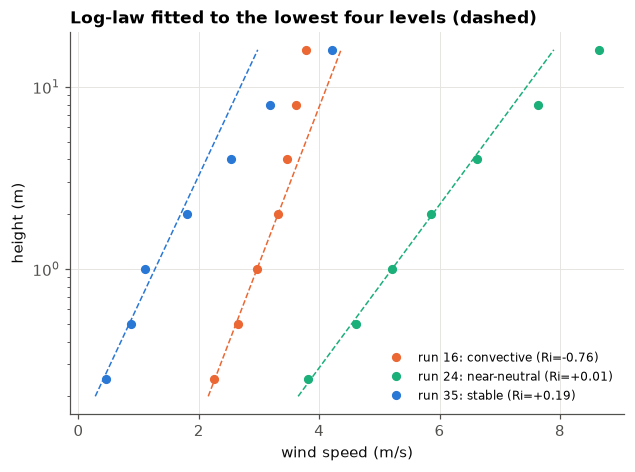

In [6]:
pick = {"convective": rt[rt.regime == "convective"].Ri_b.idxmin(),
        "near-neutral": rt[rt.regime == "near-neutral"].Ri_b.abs().idxmin(),
        "stable": rt[(rt.regime == "stable") & (rt.u_ref > 1.5)].Ri_b.idxmax()}   # skip the near-calm runs
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for reg, run in pick.items():
    row = U.loc[run].dropna(); row = row[row > 0]
    ax.plot(row.values, row.index, "o", color=colors[reg], label=f"run {run}: {reg} (Ri={rt.Ri_b[run]:+.2f})")
    z = np.array([h for h in [0.25, 0.5, 1.0, 2.0] if h in row.index])
    b, a = np.polyfit(np.log(z), row[z], 1)
    zz = np.geomspace(0.2, 16, 50)
    ax.plot(a + b * np.log(zz), zz, color=colors[reg], lw=1, ls="--")
ax.set_yscale("log"); ax.set_xlabel("wind speed (m/s)"); ax.set_ylabel("height (m)")
ax.set_title("Log-law fitted to the lowest four levels (dashed)"); ax.legend(fontsize=8); plt.show()

The neutral run follows its line all the way to 16 m. The stable run accelerates aloft, above
the dashed line, because the inversion decouples the upper air from the surface drag. The
convective run falls short of its line aloft, because mixing has smoothed the profile.

### The roughness length of the prairie

The log law is only valid near neutral, so we estimate $z_0$ from the windy, near-neutral runs.
The literature value for the Prairie Grass site is about **0.6 cm**.

25 windy runs with |Ri| < 0.05:  z0 median = 0.65 cm (IQR 0.55–0.84 cm),  u* median = 0.42 m/s


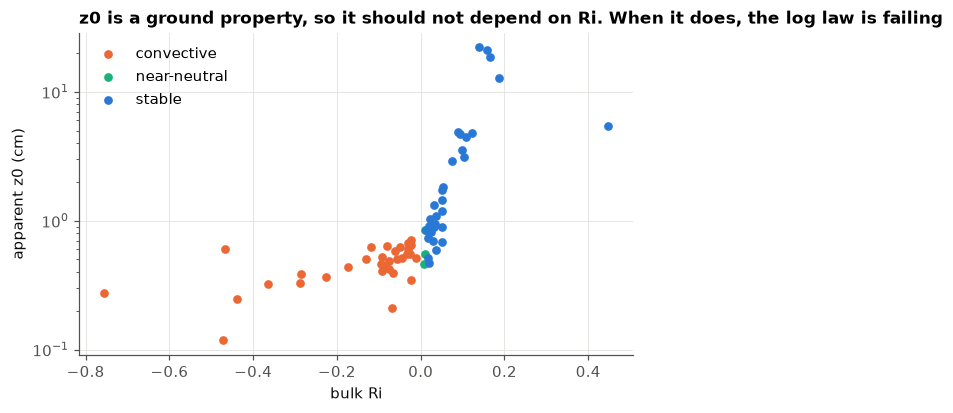

In [7]:
ok = rt[(rt.Ri_b.abs() < 0.05) & (rt.u_ref > 4)]
print(f"{len(ok)} windy runs with |Ri| < 0.05:  z0 median = {ok.z0_m.median()*100:.2f} cm "
      f"(IQR {ok.z0_m.quantile(.25)*100:.2f}–{ok.z0_m.quantile(.75)*100:.2f} cm),  u* median = {ok.u_star.median():.2f} m/s")
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for reg, g in rt.groupby("regime", observed=True):
    ax.scatter(g.Ri_b, g.z0_m * 100, color=colors[reg], label=reg, s=22)
ax.set_yscale("log"); ax.set_xlabel("bulk Ri"); ax.set_ylabel("apparent z0 (cm)")
ax.set_title("z0 is a ground property, so it should not depend on Ri. When it does, the log law is failing")
ax.legend(); plt.show()

This figure carries a lesson about *model validity*. The apparent $z_0$ is steady near Ri ≈ 0
and climbs by two orders of magnitude for stable runs. The grass did not grow overnight: the
neutral log law is the wrong model there. Monin–Obukhov similarity theory adds stability
corrections to the profile, and that is the natural next step.

## 4. Power-law exponent: a one-number summary of the wind profile

Engineers often write $u \propto z^p$. For neutral flow over grass, p ≈ 1/7 ≈ 0.14. The
exponent grows with stability, which is why regulatory models tabulate p by stability class.

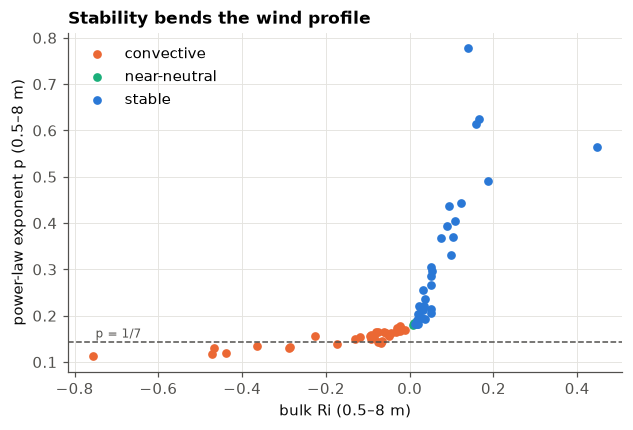

,wind_exp_p,u_star,sigma_theta_source_10,u_ref
regime,,,,
convective,0.156,0.410,10.65,6.195
near-neutral,0.182,0.412,7.10,6.220
stable,0.267,0.258,5.50,3.330


In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for reg, g in rt.groupby("regime", observed=True):
    ax.scatter(g.Ri_b, g.wind_exp_p, color=colors[reg], label=reg, s=22)
ax.axhline(1/7, color=pgdata.MUTED, ls="--", lw=1); ax.text(-0.75, 1/7 + 0.01, "p = 1/7", color=pgdata.MUTED, fontsize=8)
ax.set_xlabel("bulk Ri (0.5–8 m)"); ax.set_ylabel("power-law exponent p (0.5–8 m)")
ax.set_title("Stability bends the wind profile"); ax.legend(); plt.show()
rt.groupby("regime", observed=True)[["wind_exp_p", "u_star", "sigma_theta_source_10", "u_ref"]].median()

## 5. Wind-direction fluctuations: σ_θ

σ_θ, the standard deviation of wind direction over 10 minutes, is a direct measure of
**lateral turbulence**, and so of how wide the plume will be (notebook 06). Convective eddies
swing the wind around much more than stable flow does.

Below, σ_θ is plotted against wind speed. In stable runs σ_θ stays low. In convective runs it is
largest when the wind is *weak*, because then buoyant eddies dominate over the mean flow.

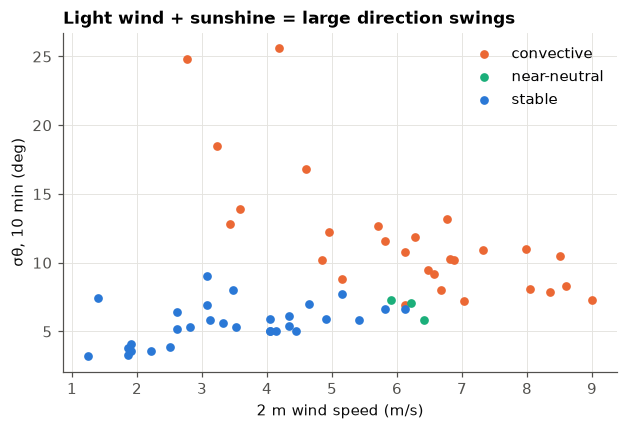

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for reg, g in rt.groupby("regime", observed=True):
    ax.scatter(g.u_ref, g.sigma_theta_source_10, color=colors[reg], label=reg, s=22)
ax.set_xlabel("2 m wind speed (m/s)"); ax.set_ylabel("σθ, 10 min (deg)"); ax.legend()
ax.set_title("Light wind + sunshine = large direction swings"); plt.show()

**Takeaways**

- Temperature gradient, radiation and Ri split the runs cleanly into convective (daytime) and
  stable (night) regimes. Only a few windy evening runs are near-neutral.
- The neutral log law fits the windy, near-neutral runs and gives $z_0$ ≈ 0.7 cm, close to the
  published 0.6 cm for the site.
- Stability shows in every profile statistic: p, apparent $z_0$, σ_θ.

Next, notebook 06 shows what this does to the plume.